# DM-2 : Boosting et cartes de saillance

Description rapide

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
from pyparsing import results
seed =42

## 0. Import du dataset MNIST

In [18]:
from sklearn.datasets import fetch_openml

X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
y = y.astype(int)

(70000, 784) (70000,)


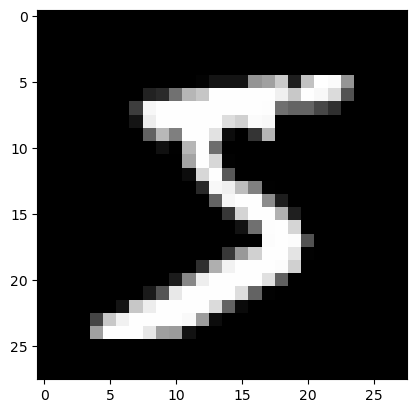

In [3]:
print(X.shape, y.shape)
plt.imshow(X[0, :].reshape(28, 28), cmap="Greys_r")

In [4]:
np.unique_counts(y)

UniqueCountsResult(values=array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), counts=array([6903, 7877, 6990, 7141, 6824, 6313, 6876, 7293, 6825, 6958]))

- 70000 images aplatis de taille (1, 784) ((28,28) à l'origine).
- Chiffre entre 0 et 9.

## 1. Utilisation d’un algorithme de boosting sur de la reconnaissance de chiﬀres manuscrits

Séparation du dataset en set d'entrainnement et de test. \
75 % en entrainnement et 25% en test, car nous avons un grand nombre d'images.

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=seed)

### A. Première modélisation

Première modelisation avec Adaboost :
- Abre de décision (profondeur maximal de 20)
- nombre d'estimateur : 20
- learning rate : 0.5

In [6]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

Tree_adaboost = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=20),
                                  n_estimators=20,
                                  learning_rate=0.5,
                                  random_state=seed)

Tree_adaboost.fit(X_train, y_train)

Tree_adaboost_score = Tree_adaboost.score(X_test, y_test)
print(f"AdaBoost score: {Tree_adaboost_score}")

AdaBoost score: 0.9636571428571429


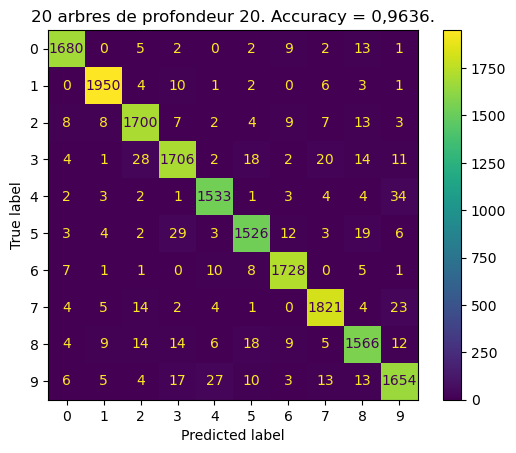

In [7]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm_Tree_adaboost = confusion_matrix(y_test, Tree_adaboost.predict(X_test))
cm_Tree_adaboost_disp = ConfusionMatrixDisplay(cm_Tree_adaboost)
cm_Tree_adaboost_disp.plot()
cm_Tree_adaboost_disp.ax_.set_title("20 arbres de profondeur 20. Accuracy = 0,9636.")
plt.savefig("images/cm_Tree_adaboost.png", dpi=300, bbox_inches="tight")

<img src="images/cm_Tree_adaboost.png" alt= "Matrice de confusion décision stump" width="500">

Avec ce premier modèle, on obtient un un score de 0,9636 en test. La matrice de confusion montre de bon resultats avec une majorité de bon classement, surtout pour les 1. Les chiffres les moins bien classées sont les 4, 5 et 8. \
\
Les principales confusions sont :
- les 5 confondu avec des 3
- les 3 confondu avec des 2
- les 9 confondu avec des 4

### B. Gridsearch en variant les classifier faibles

Stratification pour la cross-validation.

In [20]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
folds = skf.split(X_train, y_train)

Réglage des paramètres à teste en GridSearch. On test un nombre d'estimateur faible entre 5 et 100.

In [22]:
from sklearn.linear_model import Perceptron

estimators = {"stump": DecisionTreeClassifier(max_depth=1),
              "tree_d2": DecisionTreeClassifier(max_depth=2),
              "tree_d3": DecisionTreeClassifier(max_depth=3),
              "tree_d5": DecisionTreeClassifier(max_depth=5),
              "tree_d20": DecisionTreeClassifier(max_depth=20),
              "perceptron": Perceptron(max_iter=1000, tol=1e-3, random_state=seed)}

params = {"n_estimators" : [5, 10, 20, 50, 100]}

Réalisation de la cross validation GridSearch. Attention les calculs sont assez long.

[{'estimator': 'stump', 'accuracy': np.float64(0.7273333333333334), 'n_estimators': 100}]
[{'estimator': 'stump', 'accuracy': np.float64(0.7273333333333334), 'n_estimators': 100}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.8230857142857143), 'n_estimators': 100}]
[{'estimator': 'stump', 'accuracy': np.float64(0.7273333333333334), 'n_estimators': 100}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.8230857142857143), 'n_estimators': 100}, {'estimator': 'tree_d3', 'accuracy': np.float64(0.8714285714285713), 'n_estimators': 100}]
[{'estimator': 'stump', 'accuracy': np.float64(0.7273333333333334), 'n_estimators': 100}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.8230857142857143), 'n_estimators': 100}, {'estimator': 'tree_d3', 'accuracy': np.float64(0.8714285714285713), 'n_estimators': 100}, {'estimator': 'tree_d5', 'accuracy': np.float64(0.9278285714285713), 'n_estimators': 100}]
[{'estimator': 'stump', 'accuracy': np.float64(0.7273333333333334), 'n_estimators': 100}, {'es

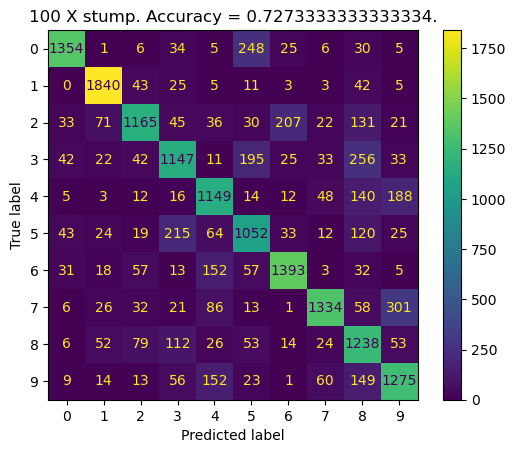

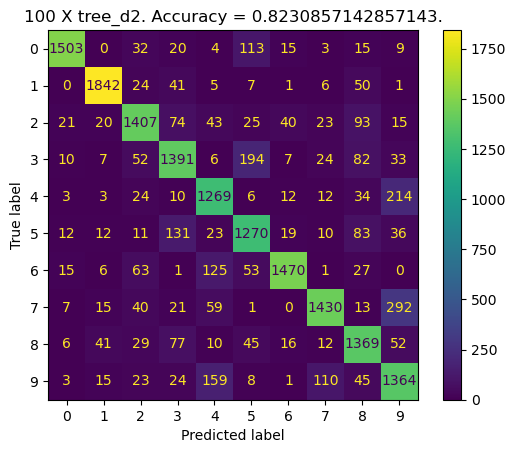

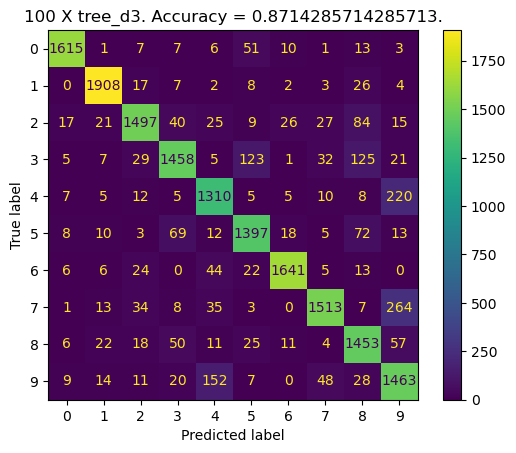

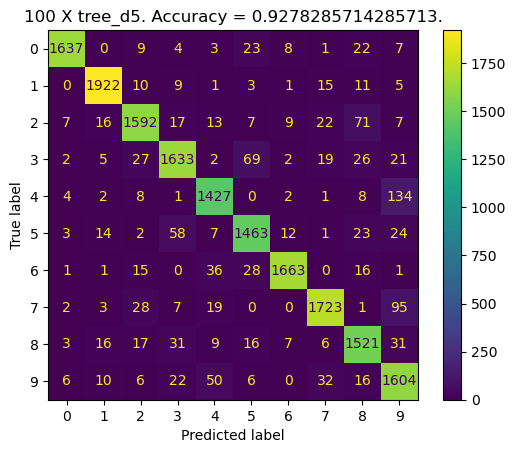

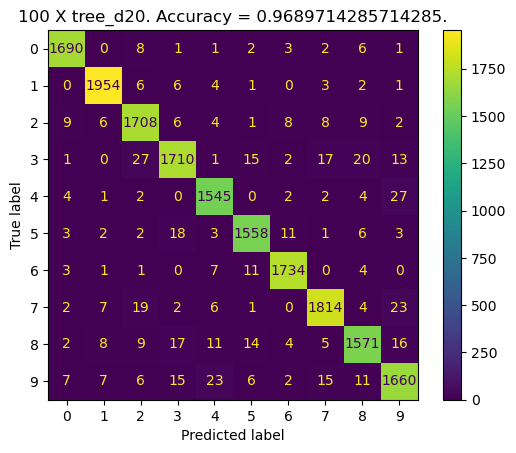

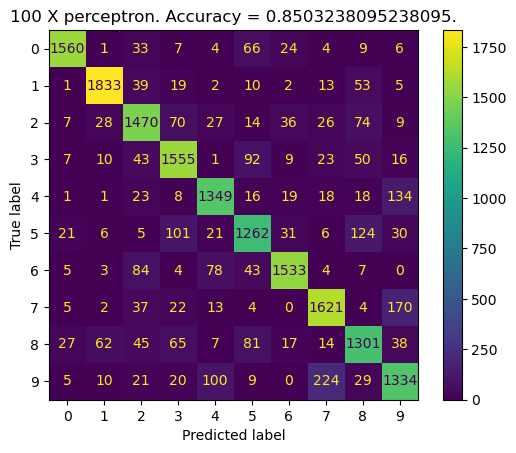

In [23]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

results = []
best_results = []

for estimator_name, estimator in estimators.items():
    ada_boost = AdaBoostClassifier(estimator=estimator, random_state=seed)

    grid = GridSearchCV(estimator=ada_boost, param_grid=params, scoring="accuracy", cv=skf, n_jobs=-1)

    grid.fit(X_train, y_train)
    acc = grid.best_score_
    best = grid.best_estimator_

    # Resultats des cross val
    best_results.append({"estimator" : estimator_name, "accuracy" : acc, "n_estimators" : grid.best_params_["n_estimators"]}) # Meilleurs résultats
    print(best_results)

    df_cv = pd.DataFrame(grid.cv_results_) # Ensemble des résultats
    df_cv["estimator"] = estimator_name
    results.append(df_cv)

    # Matrice de confusion sur le test
    n_estimators = grid.best_params_["n_estimators"]
    cm = confusion_matrix(y_test, best.predict(X_test))
    disp_cm = ConfusionMatrixDisplay(cm)
    disp_cm.plot()
    disp_cm.ax_.set_title(f"{n_estimators} X {estimator_name}. Accuracy = {acc}.")
    plt.savefig(f"images/cm_{estimator_name}.png", dpi=300, bbox_inches="tight")

Construction d'un dataframe avec les resultats de la recherche.

In [ ]:
df_cv_all = pd.concat(results, ignore_index=True)
df_accuracy = (df_cv_all.rename(columns={"param_n_estimators": "n_estimators", "mean_test_score": "accuracy_cv", "std_test_score": "std_cv"})[["estimator", "n_estimators", "accuracy_cv", "std_cv"]].sort_values(["estimator", "n_estimators"]).reset_index(drop=True))
df_accuracy

Creation d'un dataframe avec les meilleurs résultats de la recherche.

In [24]:
df_best_results = pd.DataFrame(best_results, columns=["estimator", "accuracy", "n_estimators"])
df_best_results

,estimator,accuracy,n_estimators
0,stump,0.727333,100
1,tree_d2,0.823086,100
2,tree_d3,0.871429,100
3,tree_d5,0.927829,100
4,tree_d20,0.968971,100
5,perceptron,0.850324,100


<img src="images/cm_stump.png" alt= "Matrice de confusion décision stump" width="500">

<img src="images/cm_tree_d2.png" alt= "Matrice de confusion arbre de profondeur 2" width="500">

<img src="images/cm_tree_d3.png" alt= "Matrice de confusion arbre de profondeur 3" width="500">

<img src="images/cm_tree_d5.png" alt= "Matrice de confusion arbre de profondeur 5" width="500">

<img src="images/cm_tree_d20.png" alt= "Matrice de confusion arbre de profondeur 20" width="500">

<img src="images/cm_perceptron.png" alt= "Matrice de confusion perceptron" width="500">

### C. Etude de classes binaires

On test ici les classes :
- 9 vs 4
- 5 vs 3

#### 1. 9 vs 4

In [25]:
mask_9v4 = (y==9) | (y==4)
X_9v4, y_9v4 = X[mask_9v4], (y[mask_9v4] == 9).astype(int)
X_9v4_train, X_9v4_test, y_9v4_train, y_9v4_test = train_test_split(X_9v4, y_9v4, test_size=0.25, random_state=seed)
print(np.unique_counts(y_9v4))


UniqueCountsResult(values=array([0, 1]), counts=array([6824, 6958]))


In [13]:
results_9v4 = []

for estimator_name, estimator in estimators.items():
    ada_boost = AdaBoostClassifier(estimator=estimator, random_state=seed)

    grid = GridSearchCV(estimator=ada_boost, param_grid={"n_estimators" : [20]}, scoring="accuracy", cv=skf, n_jobs=-1)

    grid.fit(X_9v4_train, y_9v4_train)
    acc = grid.best_score_

    results_9v4.append({"estimator" : estimator_name, "accuracy" : acc, "n_estimators" : grid.best_params_["n_estimators"]})
    print(results_9v4)

[{'estimator': 'stump', 'accuracy': np.float64(0.9291789837353868), 'n_estimators': 20}]
[{'estimator': 'stump', 'accuracy': np.float64(0.9291789837353868), 'n_estimators': 20}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.958979412130757), 'n_estimators': 20}]
[{'estimator': 'stump', 'accuracy': np.float64(0.9291789837353868), 'n_estimators': 20}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.958979412130757), 'n_estimators': 20}, {'estimator': 'tree_d3', 'accuracy': np.float64(0.9717491126563788), 'n_estimators': 20}]
[{'estimator': 'stump', 'accuracy': np.float64(0.9291789837353868), 'n_estimators': 20}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.958979412130757), 'n_estimators': 20}, {'estimator': 'tree_d3', 'accuracy': np.float64(0.9717491126563788), 'n_estimators': 20}, {'estimator': 'tree_d5', 'accuracy': np.float64(0.9810368141158989), 'n_estimators': 20}]
[{'estimator': 'stump', 'accuracy': np.float64(0.9291789837353868), 'n_estimators': 20}, {'estimator': 'tre

#### 2. 5 vs 3

In [26]:
mask_5v3 = (y==5) | (y==3)
X_5v3, y_5v3 = X[mask_5v3], (y[mask_5v3] == 5).astype(int)
X_5v3_train, X_5v3_test, y_5v3_train, y_5v3_test = train_test_split(X_5v3, y_5v3, test_size=0.25, random_state=seed)
print(np.unique_counts(y_5v3))

UniqueCountsResult(values=array([0, 1]), counts=array([7141, 6313]))


In [15]:
results_5v3 = []

for estimator_name, estimator in estimators.items():
    ada_boost = AdaBoostClassifier(estimator=estimator, random_state=seed)

    grid = GridSearchCV(estimator=ada_boost, param_grid={"n_estimators" : [20]}, scoring="accuracy", cv=skf, n_jobs=-1)

    grid.fit(X_5v3_train, y_5v3_train)
    acc = grid.best_score_

    results_5v3.append({"estimator" : estimator_name, "accuracy" : acc, "n_estimators" : grid.best_params_["n_estimators"]})
    print(results_5v3)

[{'estimator': 'stump', 'accuracy': np.float64(0.894350842418236), 'n_estimators': 20}]
[{'estimator': 'stump', 'accuracy': np.float64(0.894350842418236), 'n_estimators': 20}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.951139742319128), 'n_estimators': 20}]
[{'estimator': 'stump', 'accuracy': np.float64(0.894350842418236), 'n_estimators': 20}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.951139742319128), 'n_estimators': 20}, {'estimator': 'tree_d3', 'accuracy': np.float64(0.9706640237859266), 'n_estimators': 20}]
[{'estimator': 'stump', 'accuracy': np.float64(0.894350842418236), 'n_estimators': 20}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.951139742319128), 'n_estimators': 20}, {'estimator': 'tree_d3', 'accuracy': np.float64(0.9706640237859266), 'n_estimators': 20}, {'estimator': 'tree_d5', 'accuracy': np.float64(0.9851337958374629), 'n_estimators': 20}]
[{'estimator': 'stump', 'accuracy': np.float64(0.894350842418236), 'n_estimators': 20}, {'estimator': 'tree_d2'

#### 3. Groupes de chiffre

## 2. Réalisation de cartes de saillance

## 3. Embedding

Elaboration d'un ensemble de test réduit pour raccourcir les temps de calculs.

In [46]:
N_TRAIN = 8000           # taille du sous-échantillon train
N_TEST = int(0.25 * N_TRAIN)  # taille du sous-échantillon test

rng = np.random.default_rng(seed)
idx_tr = rng.choice(len(X_train), N_TRAIN, replace=False)
idx_te = rng.choice(len(X_test), N_TEST, replace=False)
X_train_FR, y_train_FR = X_train[idx_tr], y_train[idx_tr]
X_test_FR, y_test_FR = X_test[idx_te], y_test[idx_te]

#### 1. Entrainnement d'un MLP

Apprentissage d'un perceptron multicouche à 1 couche cahé.

In [47]:
from sklearn.neural_network import MLPRegressor

n_hidden = 64

def train_auto_associator(X_train, n_hidden, seed=seed):
    mlp = MLPRegressor(
        hidden_layer_sizes=(n_hidden,),
        activation="relu",          # fonction d'activagion cachée = relu
        solver="adam",
        max_iter=1000,
        early_stopping=True,        # coupe sur la MSE de reconstruction
        n_iter_no_change=10,
        random_state=seed,
        verbose=True,
        )
    mlp.fit(X_train, X_train)
    return mlp

On réalise une fonction d'embedding.

In [48]:
def embed(mlp, X):
    """Activités de la couche cachée = description dans l'espace de
    redescription. Identique à h = relu(X @ W1 + b1)."""
    Z = X @ mlp.coefs_[0] + mlp.intercepts_[0]
    return np.maximum(Z, 0.0)

On crée une fonction de reconstruction vers l'espace original.

In [49]:
def reconstruct(mlp, X):
    """Sortie du réseau complet (reconstruction 784 pixels)."""
    return embed(mlp, X) @ mlp.coefs_[1] + mlp.intercepts_[1]

Visualisation des images.

In [52]:
autoenc = train_auto_associator(X_test_FR, n_hidden)
recon = reconstruct(autoenc, X_test_FR)

img_idx = 0                                             # image de test choisie
img = X_test[img_idx]
img_rec = reconstruct(autoenc, img[None, :]).reshape(28, 28)

fig, axes = plt.subplots(1, 2, figsize=(6, 3.2))
axes[0].imshow(img.reshape(28, 28), cmap="gray")
axes[0].set_title(f"original (test, label {y_test[img_idx]})")
axes[1].imshow(img_rec, cmap="gray")
axes[1].set_title(f"reconstruit ({n_hidden} neurones)")
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Auto-association 784->{n_hidden}->784")
fig.tight_layout()
plt.savefig("images/image1_autoencodage.png", dpi=300, bbox_inches="tight")
plt.close(fig)


Iteration 1, loss = 3634.61021778
Validation score: -3.986555
Iteration 2, loss = 2856.51310654
Validation score: -5.225693
Iteration 3, loss = 2267.82963682
Validation score: -2.526093
Iteration 4, loss = 2047.88541254
Validation score: -2.124248
Iteration 5, loss = 1911.46771664
Validation score: -1.870802
Iteration 6, loss = 1770.89547085
Validation score: -1.729927
Iteration 7, loss = 1629.20097885
Validation score: -1.562611
Iteration 8, loss = 1498.74228542
Validation score: -1.310692
Iteration 9, loss = 1380.43285275
Validation score: -1.168020
Iteration 10, loss = 1278.40992307
Validation score: -1.103798
Iteration 11, loss = 1191.33794078
Validation score: -0.978198
Iteration 12, loss = 1117.59794926
Validation score: -0.876297
Iteration 13, loss = 1052.23909042
Validation score: -0.748605
Iteration 14, loss = 995.55823631
Validation score: -0.660243
Iteration 15, loss = 945.63199567
Validation score: -0.606445
Iteration 16, loss = 901.53344293
Validation score: -0.469157
Iter

#### 2. AdaBoost

Création des datasets embed

In [60]:
E_train_FR = embed(autoenc, X_train_FR)
E_test_FR = embed(autoenc, X_test_FR)
print(f"Embedding train: {E_train_FR.shape}, test: {E_test_FR.shape}")

Embedding train: (8000, 64), test: (2000, 64)


Paramètres à tester

In [57]:
from sklearn.linear_model import Perceptron

estimators = {"stump": DecisionTreeClassifier(max_depth=1),
              "tree_d2": DecisionTreeClassifier(max_depth=2),
              "tree_d5": DecisionTreeClassifier(max_depth=5),
              "tree_d20": DecisionTreeClassifier(max_depth=20),
              "perceptron": Perceptron(max_iter=1000, tol=1e-3, random_state=seed)}

params = {"n_estimators" : [50, 100]}

Gridsearch sur l'embedding.

[{'estimator': 'stump', 'accuracy': np.float64(0.63375), 'n_estimators': 100}]
[{'estimator': 'stump', 'accuracy': np.float64(0.63375), 'n_estimators': 100}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.711125), 'n_estimators': 100}]
[{'estimator': 'stump', 'accuracy': np.float64(0.63375), 'n_estimators': 100}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.711125), 'n_estimators': 100}, {'estimator': 'tree_d5', 'accuracy': np.float64(0.841375), 'n_estimators': 100}]
[{'estimator': 'stump', 'accuracy': np.float64(0.63375), 'n_estimators': 100}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.711125), 'n_estimators': 100}, {'estimator': 'tree_d5', 'accuracy': np.float64(0.841375), 'n_estimators': 100}, {'estimator': 'tree_d20', 'accuracy': np.float64(0.8643750000000001), 'n_estimators': 100}]
[{'estimator': 'stump', 'accuracy': np.float64(0.63375), 'n_estimators': 100}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.711125), 'n_estimators': 100}, {'estimator': 'tree_d5', 'a

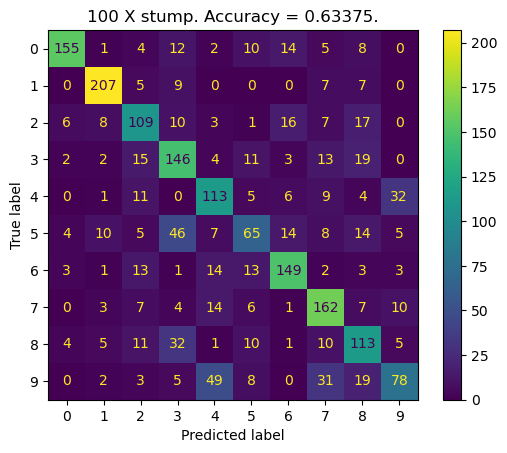

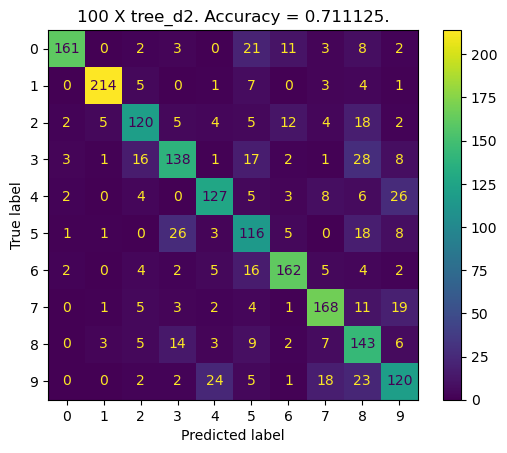

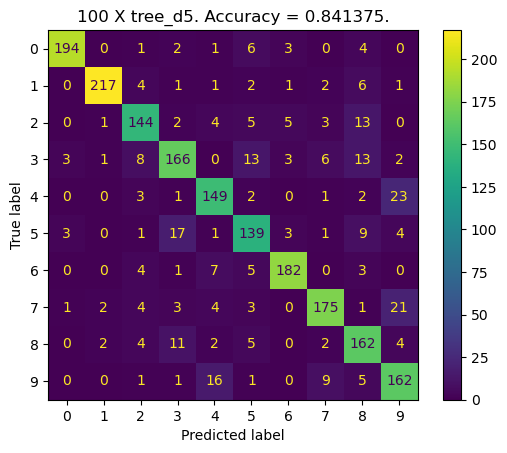

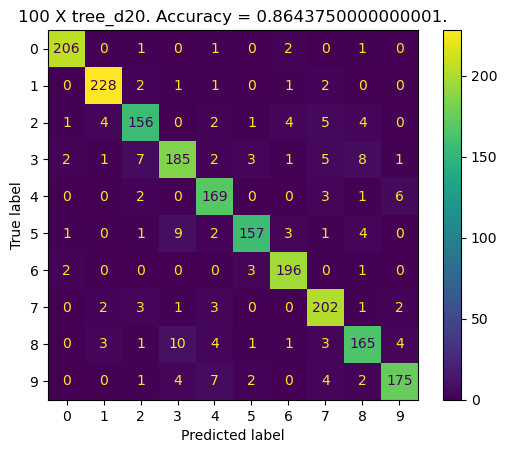

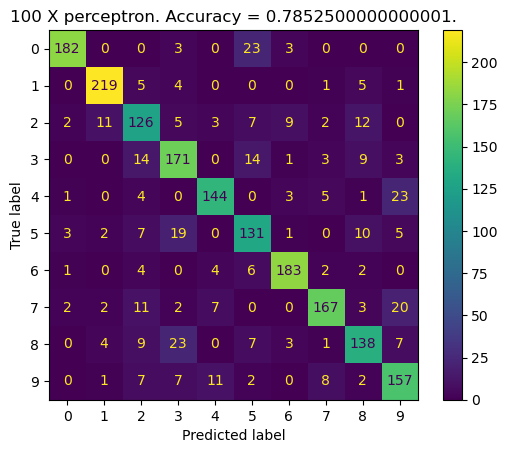

In [59]:
from sklearn.model_selection import GridSearchCV

results_embed = []
best_results_embed = []

for estimator_name, estimator in estimators.items():
    ada_boost = AdaBoostClassifier(estimator=estimator, random_state=seed)

    grid = GridSearchCV(estimator=ada_boost, param_grid=params, scoring="accuracy", cv=skf, n_jobs=-1)

    grid.fit(E_train_FR, y_train_FR)
    acc = grid.best_score_
    best = grid.best_estimator_

    # Resultats des cross val
    best_results_embed.append({"estimator" : estimator_name, "accuracy" : acc, "n_estimators" : grid.best_params_["n_estimators"]}) # Meilleurs résultats
    print(best_results_embed)

    df_cv = pd.DataFrame(grid.cv_results_) # Ensemble des résultats
    df_cv["estimator"] = estimator_name
    results_embed.append(df_cv)

    # Matrice de confusion sur le test
    n_estimators = grid.best_params_["n_estimators"]
    cm = confusion_matrix(y_test_FR, best.predict(E_test_FR))
    disp_cm = ConfusionMatrixDisplay(cm)
    disp_cm.plot()
    disp_cm.ax_.set_title(f"{n_estimators} X {estimator_name}. Accuracy = {acc}.")
    plt.savefig(f"images/cm_embedding_{estimator_name}.png", dpi=300, bbox_inches="tight")